## Setup

In [1]:
import json
import os
import platform
import random
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from tqdm.auto import tqdm
import torch

/home/yomna.elnikety/.conda/envs/a2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Change only this line when running notebook
DATA_ROOT = Path("Task01_BrainTumour")

# The supplied split file is placed along with the notebook
SPLIT_FILE = Path("assignment2_split.csv")

CACHE_ROOT = DATA_ROOT.parent / "cache_preproc"
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

EXPECTED_N_CASES = 484
SEED = 42
CROP_MARGIN = 8
PATCH = (96, 96, 96)

In [ ]:
# Seed every random number generator used
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# Environment log for README
print("Python         :", platform.python_version())
print("NumPy          :", np.__version__)
print("nibabel        :", nib.__version__)
print("PyTorch        :", torch.__version__)
print("CPU cores seen :", os.cpu_count())
print("CUDA available :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU in this session")
print("Seed           :", SEED)

Python         : 3.11.17
NumPy          : 2.4.6
nibabel        : 5.4.2
PyTorch        : 2.11.0+cu128
CPU cores seen : 48
CUDA available : True | NVIDIA RTX 5000 Ada Generation
Seed           : 42


In [4]:
# Helper used throughout the notebook, open one case's image and label as nibabel objects, nibabel is lazy so only the header is read here, the voxel data is read when np.asanyarray(img.dataobj) is called
def load_case(row):
    img = nib.load(DATA_ROOT / row.image_relpath)
    lab = nib.load(DATA_ROOT / row.label_relpath)
    return img, lab
    
split_df = pd.read_csv(SPLIT_FILE)
print(split_df.head(3).to_string(index=False))

  case_id split             image_relpath             label_relpath
BRATS_001 train imagesTr/BRATS_001.nii.gz labelsTr/BRATS_001.nii.gz
BRATS_002  test imagesTr/BRATS_002.nii.gz labelsTr/BRATS_002.nii.gz
BRATS_003 train imagesTr/BRATS_003.nii.gz labelsTr/BRATS_003.nii.gz


## Task A - Define the task and inspect the volumes

In [5]:
with open(DATA_ROOT / "dataset.json") as f:
    meta = json.load(f)

names = [meta["modality"][str(i)] for i in range(len(meta["modality"]))]

print("Channel order (index -> name):", meta["modality"])
print("Label values  (value -> name):", meta["labels"])

Channel order (index -> name): {'0': 'FLAIR', '1': 'T1w', '2': 't1gd', '3': 'T2w'}
Label values  (value -> name): {'0': 'background', '1': 'edema', '2': 'non-enhancing tumor', '3': 'enhancing tumour'}


In [6]:
# Inspect three cases
inspect_rows = list(split_df[split_df.split == "train"].head(3).itertuples())

records = []
for row in inspect_rows:
    img, lab = load_case(row)
    lab_arr = np.asanyarray(lab.dataobj)

    # The affine maps voxel indices to physical coordinates in mm
    print(f"\n=== {row.case_id} ===")
    print("image shape (H, W, D, C) :", img.shape)
    print("label shape (H, W, D)    :", lab.shape)
    print("channel order            :", names)
    print("orientation codes        :", nib.aff2axcodes(img.affine))
    print("voxel spacing (mm)       :", tuple(float(z) for z in img.header.get_zooms()[:3]))
    print("affine matrix:\n", np.round(img.affine, 3))
    print("label values present     :", np.unique(lab_arr))

    records.append({
        "case": row.case_id,
        "image shape": img.shape,
        "label shape": lab.shape,
        "orientation": "".join(nib.aff2axcodes(img.affine)),
        "spacing (mm)": tuple(float(z) for z in img.header.get_zooms()[:3]),
        "label values": [int(v) for v in np.unique(lab_arr)],
        "image/label affine equal": bool(np.allclose(img.affine, lab.affine)),
    })

pd.DataFrame(records)


=== BRATS_001 ===
image shape (H, W, D, C) : (240, 240, 155, 4)
label shape (H, W, D)    : (240, 240, 155)
channel order            : ['FLAIR', 'T1w', 't1gd', 'T2w']
orientation codes        : ('R', 'A', 'S')
voxel spacing (mm)       : (1.0, 1.0, 1.0)
affine matrix:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
label values present     : [0 1 2 3]

=== BRATS_003 ===
image shape (H, W, D, C) : (240, 240, 155, 4)
label shape (H, W, D)    : (240, 240, 155)
channel order            : ['FLAIR', 'T1w', 't1gd', 'T2w']
orientation codes        : ('R', 'A', 'S')
voxel spacing (mm)       : (1.0, 1.0, 1.0)
affine matrix:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
label values present     : [0 1 2 3]

=== BRATS_004 ===
image shape (H, W, D, C) : (240, 240, 155, 4)
label shape (H, W, D)    : (240, 240, 155)
channel order            : ['FLAIR', 'T1w', 't1gd', 'T2w']
orientation codes        : ('R', 'A', 'S')
voxel spacing (mm)       : (1.0, 1.0, 1.0)
affine matrix

,case,image shape,label shape,orientation,spacing (mm),label values,image/label affine equal
0,BRATS_001,"(240, 240, 155, 4)","(240, 240, 155)",RAS,"(1.0, 1.0, 1.0)","[0, 1, 2, 3]",True
1,BRATS_003,"(240, 240, 155, 4)","(240, 240, 155)",RAS,"(1.0, 1.0, 1.0)","[0, 1, 2, 3]",True
2,BRATS_004,"(240, 240, 155, 4)","(240, 240, 155)",RAS,"(1.0, 1.0, 1.0)","[0, 1, 2, 3]",True


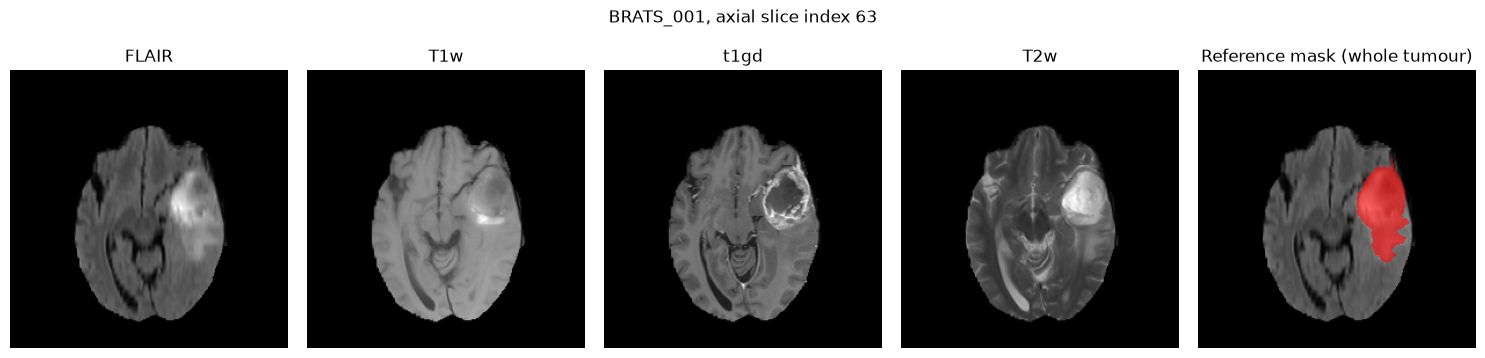

In [7]:
# Figure
row = inspect_rows[0]
img, lab = load_case(row)
vol = np.asanyarray(img.dataobj)
msk = np.asanyarray(lab.dataobj)

# Choose the axial slice with the largest tumour area so the tumour is clearly visible.
z = int(np.argmax((msk > 0).sum(axis=(0, 1))))

fig, axs = plt.subplots(1, 5, figsize=(15, 3.4))
for i in range(4):
    # np.rot90 only turns the picture so that anterior is at the top
    axs[i].imshow(np.rot90(vol[:, :, z, i]), cmap="gray")
    axs[i].set_title(names[i])

# Last panel for reference whole-tumour mask overlaid on flair.
axs[4].imshow(np.rot90(vol[:, :, z, 0]), cmap="gray")
axs[4].imshow(np.ma.masked_equal(np.rot90(msk[:, :, z] > 0), 0), cmap="autumn", alpha=0.6)
axs[4].set_title("Reference mask (whole tumour)")

for a in axs:
    a.axis("off")
fig.suptitle(f"{row.case_id}, axial slice index {z}", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_modalities.png", dpi=200, bbox_inches="tight")
plt.show()

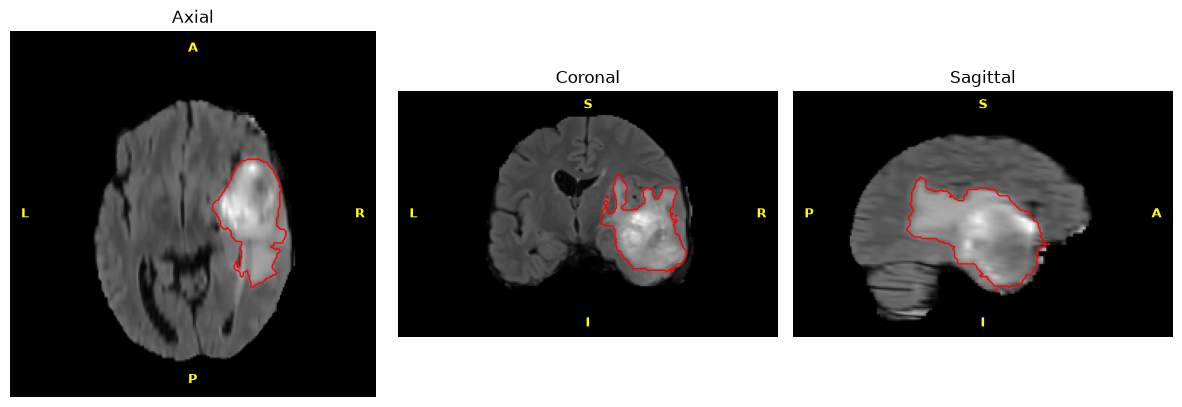

In [8]:
# Figure
img_c = nib.as_closest_canonical(img)
lab_c = nib.as_closest_canonical(lab)
flair = np.asanyarray(img_c.dataobj)[..., 0]
mask3d = np.asanyarray(lab_c.dataobj) > 0

sx, sy, sz = img_c.header.get_zooms()[:3]

# Show all three views of the tumour
cx, cy, cz = [int(np.median(idx)) for idx in np.nonzero(mask3d)]

# Writes anatomical direction letters on the image edges
def label_directions(ax, top, bottom, left, right):
    kw = dict(color="yellow", fontsize=9, fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.97, top, ha="center", va="top", **kw)
    ax.text(0.5, 0.03, bottom, ha="center", va="bottom", **kw)
    ax.text(0.03, 0.5, left, ha="left", va="center", **kw)
    ax.text(0.97, 0.5, right, ha="right", va="center", **kw)

views = [
    ("Axial",    flair[:, :, cz], mask3d[:, :, cz], sy / sx, ("A", "P", "L", "R")),
    ("Coronal",  flair[:, cy, :], mask3d[:, cy, :], sz / sx, ("S", "I", "L", "R")),
    ("Sagittal", flair[cx, :, :], mask3d[cx, :, :], sz / sy, ("S", "I", "P", "A")),
]

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, sl, mk, aspect, dirs) in zip(axs, views):
    ax.imshow(np.rot90(sl), cmap="gray", aspect=aspect)
    ax.contour(np.rot90(mk), levels=[0.5], colors="r", linewidths=1)
    label_directions(ax, *dirs)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_three_planes.png", dpi=200, bbox_inches="tight")
plt.show()

## Task B – Create a reproducible case-level split

In [9]:
assert len(split_df) == EXPECTED_N_CASES, "unexpected number of cases"
assert set(split_df["split"]) == {"train", "validation", "test"}, "unexpected split names"
assert split_df["case_id"].is_unique, "a case id appears more than once"

for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists(), f"missing image: {row.image_relpath}"
    assert (DATA_ROOT / row.label_relpath).exists(), f"missing label: {row.label_relpath}"

# Case identifiers must be disjoint across the three splits
ids = {s: set(g["case_id"]) for s, g in split_df.groupby("split")}
assert not (ids["train"] & ids["validation"]), "train/validation overlap"
assert not (ids["train"] & ids["test"]), "train/test overlap"
assert not (ids["validation"] & ids["test"]), "validation/test overlap"
print("OK: all files exist, case IDs are unique and disjoint across train / validation / test.")

OK: all files exist, case IDs are unique and disjoint across train / validation / test.


In [10]:
#Case counts per split.
counts = split_df["split"].value_counts().reindex(["train", "validation", "test"])
print(pd.DataFrame({"cases": counts, "share (%)": (100 * counts / counts.sum()).round(1)}))

            cases  share (%)
split                       
train         338       69.8
validation     73       15.1
test           73       15.1


In [11]:
# Distribution of reference tumour volume in each split.
def tumour_volume_ml(row):
    lab = nib.load(DATA_ROOT / row.label_relpath)
    voxel_ml = float(np.prod(lab.header.get_zooms()[:3])) / 1000.0
    return float((np.asanyarray(lab.dataobj) > 0).sum()) * voxel_ml

volume_df = split_df.copy()
volume_df["tumour_ml"] = [tumour_volume_ml(r) for r in tqdm(list(volume_df.itertuples()), desc="tumour volumes")]

volume_table = (volume_df.groupby("split")["tumour_ml"]
                .describe()[["count", "mean", "std", "min", "50%", "max"]]
                .reindex(["train", "validation", "test"]).round(1))
print(volume_table)

tumour volumes: 100%|████████████████████████████████████████████████████████████████████████| 484/484 [00:11<00:00, 42.71it/s]

            count   mean   std   min   50%    max
split                                            
train       338.0  103.0  57.0   8.5  95.5  265.3
validation   73.0  100.8  63.0   7.3  91.6  266.9
test         73.0  107.4  66.3  10.1  89.1  318.3


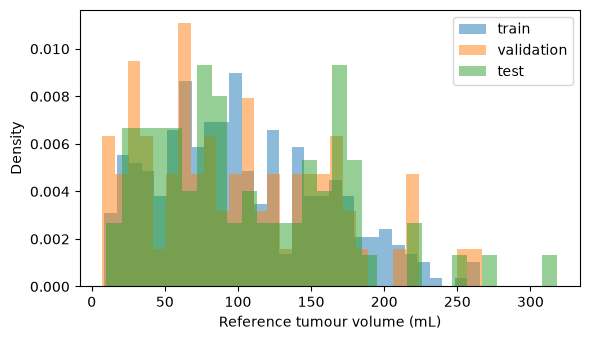

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for s in ["train", "validation", "test"]:
    ax.hist(volume_df.loc[volume_df.split == s, "tumour_ml"], bins=30, alpha=0.5, density=True, label=s)
ax.set_xlabel("Reference tumour volume (mL)")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_split_volume_hist.png", dpi=200, bbox_inches="tight")
plt.show()

## Task C – Preprocess MRI and labels safely

In [13]:
geometry_counter = Counter()
for row in tqdm(list(split_df.itertuples()), desc="geometry check"):
    img_, lab_ = load_case(row)
    same_grid = bool(np.allclose(img_.affine, lab_.affine) and img_.shape[:3] == lab_.shape)
    key = (img_.shape,
           tuple(float(np.round(z, 3)) for z in img_.header.get_zooms()[:3]),
           "".join(nib.aff2axcodes(img_.affine)),
           same_grid)
    geometry_counter[key] += 1

for key, n in geometry_counter.items():
    print(f"{n:4d} cases | shape {key[0]} | spacing {key[1]} mm | orientation {key[2]} | image & label share grid: {key[3]}")

# Decision to resample only if cases differ from each other or image and label disagree.
needs_resampling = (len(geometry_counter) != 1) or (not list(geometry_counter)[0][3])
assert not needs_resampling, "Geometry differs between cases, define one target grid and resample before continuing."

# One grid for everything so no resampling is needed
NATIVE_SHAPE = list(geometry_counter)[0][0][:3]
print("\nNo resampling needed. Target grid = native grid:", NATIVE_SHAPE, "voxels at 1.0 mm isotropic spacing, RAS orientation.")

geometry check: 100%|███████████████████████████████████████████████████████████████████████| 484/484 [00:04<00:00, 116.33it/s]

 484 cases | shape (240, 240, 155, 4) | spacing (1.0, 1.0, 1.0) mm | orientation RAS | image & label share grid: True

No resampling needed. Target grid = native grid: (240, 240, 155) voxels at 1.0 mm isotropic spacing, RAS orientation.


In [14]:
demo_img, demo_lab = load_case(inspect_rows[0])
demo_labels = np.asanyarray(demo_lab.dataobj).astype(np.float32)
demo_flair = np.asanyarray(demo_img.dataobj)[..., 0].astype(np.float32)
print("original label values:", np.unique(demo_labels))

# Labels
for order, name in [(0, "nearest-neighbour (order=0)"), (1, "linear (order=1)")]:
    down = ndi.zoom(demo_labels, 0.5, order=order)
    up = ndi.zoom(down, 2.0, order=order)
    invalid = ~np.isin(up, [0, 1, 2, 3])
    print(f"{name:30s}: unique values = {len(np.unique(up)):6d} | "
          f"invalid voxels = {int(invalid.sum()):7d} ({100 * invalid.mean():.2f}% of volume) | "
          f"invalid examples = {np.round(np.unique(up[invalid])[:5], 2)}")

# Labels must use nearest-neighbour for classes

# For MRI, intensities are continuous measurements, so linear interpolation is appropriate and stays in the original range
flair_up = ndi.zoom(ndi.zoom(demo_flair, 0.5, order=1), 2.0, order=1)
print(f"\nFLAIR intensity range  original: [{demo_flair.min():.0f}, {demo_flair.max():.0f}]"
      f"  | after linear down/up: [{flair_up.min():.0f}, {flair_up.max():.0f}]")

original label values: [0. 1. 2. 3.]
nearest-neighbour (order=0)   : unique values =      4 | invalid voxels =       0 (0.00% of volume) | invalid examples = []
linear (order=1)              : unique values =  99598 | invalid voxels =  107864 (1.20% of volume) | invalid examples = [0. 0. 0. 0. 0.]

FLAIR intensity range  original: [0, 1829]  | after linear down/up: [0, 1685]


In [15]:
def zscore_nonzero(vol):
    out = np.zeros_like(vol, dtype=np.float32)
    stats = {}
    for c in range(vol.shape[-1]):
        ch = vol[..., c]
        brain = ch != 0
        assert brain.any(), "channel has no non-zero voxels"
        mu, sd = float(ch[brain].mean()), float(ch[brain].std())
        o = out[..., c]
        o[brain] = (ch[brain] - mu) / (sd + 1e-8)
        stats[f"raw_nz_mean_{c}"] = mu
        stats[f"raw_nz_std_{c}"] = sd
        stats[f"raw_all_mean_{c}"] = float(ch.mean())
        stats[f"raw_all_std_{c}"] = float(ch.std())
    return out, stats

def brain_bbox(vol, margin=CROP_MARGIN):
    nonzero_any_channel = np.any(vol != 0, axis=-1)
    idx = np.where(nonzero_any_channel)
    lo = np.array([i.min() for i in idx]) - margin
    hi = np.array([i.max() + 1 for i in idx]) + margin
    lo = np.maximum(lo, 0)
    hi = np.minimum(hi, np.array(nonzero_any_channel.shape))
    return lo, hi

# Zero-pad at the end of each spatial axis so that every axis is at least min_size
def pad_to_min(arr, min_size):
    spatial = arr.shape[-3:]
    pads = [(0, 0)] * (arr.ndim - 3) + [(0, max(0, m - s)) for s, m in zip(spatial, min_size)]
    return np.pad(arr, pads), spatial

_t = np.zeros((10, 12, 9, 2), dtype=np.float32)
_t[3:6, 4:9, 2:5, :] = 5.0
_lo, _hi = brain_bbox(_t, margin=1)
assert list(_lo) == [2, 3, 1] and list(_hi) == [7, 10, 6]
_p, _orig = pad_to_min(np.zeros((2, 5, 6, 7)), (8, 8, 8))
assert _p.shape == (2, 8, 8, 8) and _orig == (5, 6, 7)
print("helper self-checks passed")

helper self-checks passed


In [16]:
# Show the effect of normalisation on 1 case before running it on everything
vol0 = np.asanyarray(load_case(inspect_rows[0])[0].dataobj).astype(np.float32)
vol0_n, _ = zscore_nonzero(vol0)

rows_ = []
for c in range(4):
    raw_ch, norm_ch = vol0[..., c], vol0_n[..., c]
    brain = raw_ch != 0
    rows_.append({"channel": names[c],
                  "raw mean (brain)": raw_ch[brain].mean(), "raw std (brain)": raw_ch[brain].std(),
                  "norm mean (brain)": norm_ch[brain].mean(), "norm std (brain)": norm_ch[brain].std(),
                  "norm mean (all voxels)": norm_ch.mean(), "norm std (all voxels)": norm_ch.std()})
print(pd.DataFrame(rows_).round(3).to_string(index=False))

channel  raw mean (brain)  raw std (brain)  norm mean (brain)  norm std (brain)  norm mean (all voxels)  norm std (all voxels)
  FLAIR        516.273987       211.647995                0.0               1.0                     0.0                  0.408
    T1w        780.635010       206.554993               -0.0               1.0                    -0.0                  0.408
   t1gd        728.439026       239.416000               -0.0               1.0                    -0.0                  0.408
    T2w        471.843994       211.000000               -0.0               1.0                    -0.0                  0.408


In [17]:
# Preprocess every case once and cache the result to disk
def preprocess_case(row):
    img, lab = load_case(row)
    vol = np.asanyarray(img.dataobj).astype(np.float32)
    seg = np.asanyarray(lab.dataobj).astype(np.uint8)
    assert np.isfinite(vol).all(), f"{row.case_id}: NaN/inf in image"

    lo, hi = brain_bbox(vol)
    crop = tuple(slice(a, b) for a, b in zip(lo, hi))
    vol_n, stats = zscore_nonzero(vol)

    img_c = np.ascontiguousarray(np.moveaxis(vol_n[crop], -1, 0), dtype=np.float16)
    lab_c = np.ascontiguousarray(seg[crop])

    assert int(seg.astype(np.int64).sum()) == int(lab_c.astype(np.int64).sum()), f"{row.case_id}: crop cut tumour"

    np.save(CACHE_ROOT / f"{row.case_id}_img.npy", img_c)
    np.save(CACHE_ROOT / f"{row.case_id}_lab.npy", lab_c)
    return dict(case_id=row.case_id, split=row.split,
                **{f"lo{i}": int(lo[i]) for i in range(3)},
                **{f"hi{i}": int(hi[i]) for i in range(3)},
                **stats)

INDEX_FILE = CACHE_ROOT / "cache_index.csv"
cache_ok = INDEX_FILE.exists()
if cache_ok:
    cache_df = pd.read_csv(INDEX_FILE)
    cache_ok = (len(cache_df) == EXPECTED_N_CASES and
                all((CACHE_ROOT / f"{c}_img.npy").exists() and (CACHE_ROOT / f"{c}_lab.npy").exists()
                    for c in cache_df.case_id))
if cache_ok:
    print("Reusing existing cache:", len(cache_df), "cases in", CACHE_ROOT)
else:
    records = [preprocess_case(r) for r in tqdm(list(split_df.itertuples()), desc="preprocessing")]
    cache_df = pd.DataFrame(records)
    cache_df.to_csv(INDEX_FILE, index=False)
    print("Cache written:", len(cache_df), "cases in", CACHE_ROOT)
assert len(cache_df) == EXPECTED_N_CASES

Reusing existing cache: 484 cases in cache_preproc


In [18]:
crop_shapes = np.stack([cache_df[f"hi{i}"] - cache_df[f"lo{i}"] for i in range(3)], axis=1)
native_voxels = int(np.prod(NATIVE_SHAPE))
print("Cropped shape per axis  min:", crop_shapes.min(0), "| max:", crop_shapes.max(0))
print(f"Average voxel reduction vs native grid: {100 * (1 - crop_shapes.prod(1).mean() / native_voxels):.0f}%")

train_idx = cache_df[cache_df.split == "train"]
raw_table = pd.DataFrame({
    "channel": names,
    "raw brain mean": [train_idx[f"raw_nz_mean_{c}"].mean() for c in range(4)],
    "raw brain std": [train_idx[f"raw_nz_std_{c}"].mean() for c in range(4)],
    "raw mean incl. background": [train_idx[f"raw_all_mean_{c}"].mean() for c in range(4)],
}).round(1)
print("\nRaw statistics (training-set average):")
print(raw_table.to_string(index=False))

N_CHECK = min(20, len(train_idx))
rng_check = np.random.default_rng(SEED)
check_ids = rng_check.choice(train_idx.case_id.values, size=N_CHECK, replace=False)
acc = {c: {"nz_mean": [], "nz_std": [], "all_mean": [], "all_std": []} for c in range(4)}
for cid in check_ids:
    arr = np.load(CACHE_ROOT / f"{cid}_img.npy", mmap_mode="r")
    for c in range(4):
        ch = np.asarray(arr[c], dtype=np.float32)
        brain = ch != 0
        acc[c]["nz_mean"].append(ch[brain].mean()); acc[c]["nz_std"].append(ch[brain].std())
        acc[c]["all_mean"].append(ch.mean());       acc[c]["all_std"].append(ch.std())
norm_table = pd.DataFrame({
    "channel": names,
    "brain mean": [np.mean(acc[c]["nz_mean"]) for c in range(4)],
    "brain std": [np.mean(acc[c]["nz_std"]) for c in range(4)],
    "all-voxel mean (incl. background)": [np.mean(acc[c]["all_mean"]) for c in range(4)],
    "all-voxel std (incl. background)": [np.mean(acc[c]["all_std"]) for c in range(4)],
}).round(3)
print(f"\nNormalised statistics ({N_CHECK} random training cases):")
print(norm_table.to_string(index=False))

Cropped shape per axis  min: [138 160 135] | max: [176 203 155]
Average voxel reduction vs native grid: 53%

Raw statistics (training-set average):
channel  raw brain mean  raw brain std  raw mean incl. background
  FLAIR           467.0          153.0                       74.6
    T1w           613.3          150.3                       98.6
   t1gd           617.9          159.3                       99.2
    T2w           488.7          186.4                       78.8

Normalised statistics (20 random training cases):
channel  brain mean  brain std  all-voxel mean (incl. background)  all-voxel std (incl. background)
  FLAIR        -0.0        1.0                               -0.0                             0.581
    T1w         0.0        1.0                                0.0                             0.581
   t1gd        -0.0        1.0                               -0.0                             0.581
    T2w        -0.0        1.0                               -0.0      

In [19]:
rng_rt = np.random.default_rng(SEED)
rt_ids = rng_rt.choice(cache_df.case_id.values, size=5, replace=False)
path_of = split_df.set_index("case_id")["label_relpath"]

for cid in rt_ids:
    r = cache_df[cache_df.case_id == cid].iloc[0]
    original = np.asanyarray(nib.load(DATA_ROOT / path_of[cid]).dataobj).astype(np.uint8)
    cropped = np.load(CACHE_ROOT / f"{cid}_lab.npy")
    restored = np.zeros(original.shape, np.uint8)
    restored[r.lo0:r.hi0, r.lo1:r.hi1, r.lo2:r.hi2] = cropped
    labels_ok = set(np.unique(cropped)) <= {0, 1, 2, 3}
    print(f"{cid}: round-trip identical = {np.array_equal(restored, original)} | valid label values = {labels_ok}")

BRATS_373: round-trip identical = True | valid label values = True
BRATS_212: round-trip identical = True | valid label values = True
BRATS_316: round-trip identical = True | valid label values = True
BRATS_043: round-trip identical = True | valid label values = True
BRATS_210: round-trip identical = True | valid label values = True


In [20]:
# Patch extraction helper and training-only augmentation, both are reused by the training part
def extract_patch(arr, center, size):
    spatial = arr.shape[-3:]
    out = np.zeros(arr.shape[:-3] + tuple(size), arr.dtype)
    src, dst = [], []
    for c, s, n in zip(center, size, spatial):
        a = int(c) - s // 2
        b = a + s
        sa, sb = max(a, 0), min(b, n)
        src.append(slice(sa, sb))
        dst.append(slice(sa - a, sb - a))
    out[(Ellipsis, *dst)] = arr[(Ellipsis, *src)]
    return out

class Augment3D:
    def __init__(self, p_flip=0.5, scale=(0.9, 1.1), shift=0.1, noise_std=0.05):
        self.p_flip = p_flip
        self.scale = scale
        self.shift = shift
        self.noise_std = noise_std

    def __call__(self, img, msk, rng):
        if rng.random() < self.p_flip:
            img, msk = img[:, ::-1], msk[:, ::-1]
        C = img.shape[0]
        brain = img != 0
        s = rng.uniform(*self.scale, size=(C, 1, 1, 1)).astype(np.float32)
        b = rng.uniform(-self.shift, self.shift, size=(C, 1, 1, 1)).astype(np.float32)
        img = np.where(brain, img * s + b, 0).astype(np.float32)
        noise = rng.normal(0, self.noise_std, img.shape).astype(np.float32)
        img = img + np.where(brain, noise, 0)
        return np.ascontiguousarray(img), np.ascontiguousarray(msk)

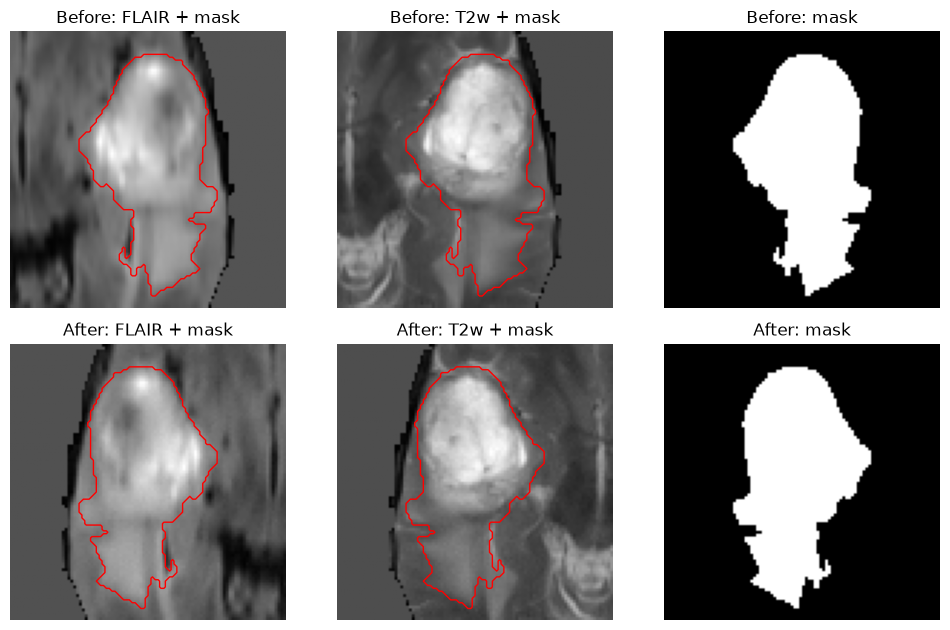

mask values after augmentation          : [0. 1.]
mask flipped consistently with the image : True
background still exactly zero            : True


In [21]:
cid = cache_df[cache_df.split == "train"].case_id.values[0]
img_cached = np.load(CACHE_ROOT / f"{cid}_img.npy").astype(np.float32)
lab_cached = np.load(CACHE_ROOT / f"{cid}_lab.npy")
centre = np.round(np.mean(np.nonzero(lab_cached > 0), axis=1)).astype(int)

patch_img = extract_patch(img_cached, centre, PATCH)
patch_msk = extract_patch((lab_cached > 0).astype(np.float32)[None], centre, PATCH)

aug_img, aug_msk = Augment3D(p_flip=1.0)(patch_img, patch_msk, np.random.default_rng(SEED))

zc = PATCH[2] // 2
fig, axs = plt.subplots(2, 3, figsize=(10, 6.4))
for r_, (im, mk, tag) in enumerate([(patch_img, patch_msk, "Before"), (aug_img, aug_msk, "After")]):
    for c_, ch in enumerate([0, 3]):
        axs[r_, c_].imshow(np.rot90(im[ch, :, :, zc]), cmap="gray")
        axs[r_, c_].contour(np.rot90(mk[0, :, :, zc]), levels=[0.5], colors="r", linewidths=1)
        axs[r_, c_].set_title(f"{tag}: {names[ch]} + mask")
    axs[r_, 2].imshow(np.rot90(mk[0, :, :, zc]), cmap="gray")
    axs[r_, 2].set_title(f"{tag}: mask")
for a in axs.ravel():
    a.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_aug_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

print("mask values after augmentation          :", np.unique(aug_msk))
print("mask flipped consistently with the image :", np.array_equal(aug_msk, patch_msk[:, ::-1]))
print("background still exactly zero            :", bool((aug_img[patch_img[:, ::-1] == 0] == 0).all()))

## Task D – Implement patch-based volumetric training

In [22]:
import importlib
from torch.utils.data import DataLoader

import a2_lib
importlib.reload(a2_lib)

TRAIN_CFG = dict(a2_lib.DEFAULT_CFG)
TRAIN_CFG.update(patch_size=PATCH, seed=SEED, cache_root=str(CACHE_ROOT))
print(pd.Series({k: v for k, v in TRAIN_CFG.items() if k not in ("sampler", "out_dir")}).to_string())

p_tumour                    0.5
patch_size         (96, 96, 96)
batch_size                    2
iters                      5000
lr                        0.001
weight_decay            0.00001
val_every                   500
log_every                    25
num_workers                   8
seed                         42
deterministic              True
amp                        True
base_filters                 16
depth                         4
cache_root        cache_preproc
max_val_cases              None
val_overlap                 0.0
val_batch_size                4


In [23]:
train_ids = cache_df.loc[cache_df.split == "train", "case_id"].tolist()
check_ds = a2_lib.PatchDataset(CACHE_ROOT, train_ids, PATCH, n_samples=8, sampler="tumour",
                               p_tumour=TRAIN_CFG["p_tumour"], augment=True, seed=SEED)
check_loader = DataLoader(check_ds, batch_size=TRAIN_CFG["batch_size"], shuffle=False, num_workers=0)
x_batch, y_batch = next(iter(check_loader))

# Expected shapes: PATCH is (H, W, D), the tensors are [B, C, D, H, W] and [B, 1, D, H, W]
expected_x = (TRAIN_CFG["batch_size"], 4, PATCH[2], PATCH[0], PATCH[1])
expected_y = (TRAIN_CFG["batch_size"], 1, PATCH[2], PATCH[0], PATCH[1])
print("image batch :", tuple(x_batch.shape), x_batch.dtype, "| expected", expected_x)
print("mask batch  :", tuple(y_batch.shape), y_batch.dtype, "| expected", expected_y)
assert tuple(x_batch.shape) == expected_x and tuple(y_batch.shape) == expected_y
assert torch.isfinite(x_batch).all(), "NaN/inf in image batch"
assert set(torch.unique(y_batch).tolist()) <= {0.0, 1.0}, "mask is not binary"

for c in range(4):
    brain = x_batch[:, c] != 0
    print(f"  channel {c} ({names[c]:5s}): brain mean {x_batch[:, c][brain].mean():+.3f}, std {x_batch[:, c][brain].std():.3f}")
print("tumour voxels per patch:", [int(v) for v in y_batch.flatten(1).sum(1)])

image batch : (2, 4, 96, 96, 96) torch.float32 | expected (2, 4, 96, 96, 96)
mask batch  : (2, 1, 96, 96, 96) torch.float32 | expected (2, 1, 96, 96, 96)
  channel 0 (FLAIR): brain mean +0.085, std 1.055
  channel 1 (T1w  ): brain mean -0.015, std 0.981
  channel 2 (t1gd ): brain mean +0.115, std 0.998
  channel 3 (T2w  ): brain mean +0.108, std 1.041
tumour voxels per patch: [40761, 27855]


In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = a2_lib.UNet3D(in_channels=4, out_channels=1, base=TRAIN_CFG["base_filters"], depth=TRAIN_CFG["depth"]).to(device)

# Sanity check
with torch.no_grad():
    dummy = torch.zeros(1, 4, 32, 32, 32, device=device)
    out = model(dummy)
assert out.shape == (1, 1, 32, 32, 32)

print("input channels  :", 4, "(FLAIR, T1w, T1gd, T2w)")
print("output channels :", out.shape[1], "(one logit per voxel; sigmoid gives tumour probability)")
print("parameters      :", f"{a2_lib.count_parameters(model):,}")
print("patch size      :", PATCH, "voxels (H, W, D) = 96 mm cube at 1 mm spacing")
print("device          :", device)

input channels  : 4 (FLAIR, T1w, T1gd, T2w)
output channels : 1 (one logit per voxel; sigmoid gives tumour probability)
parameters      : 1,445,681
patch size      : (96, 96, 96) voxels (H, W, D) = 96 mm cube at 1 mm spacing
device          : cuda


In [25]:
def patch_tumour_stats(sampler, n=400):
    ds = a2_lib.PatchDataset(CACHE_ROOT, train_ids, PATCH, n_samples=n, sampler=sampler,
                             p_tumour=TRAIN_CFG["p_tumour"], augment=False, seed=SEED)
    has_tumour, voxel_frac = [], []
    for i in range(n):
        _, y = ds[i]
        has_tumour.append(bool(y.sum() > 0))
        voxel_frac.append(float(y.mean()))
    return np.mean(has_tumour), np.mean(voxel_frac)

sampler_stats = pd.DataFrame(
    {s: patch_tumour_stats(s) for s in ["uniform", "tumour"]},
    index=["patches containing tumour", "mean tumour voxel fraction per patch"]).T.round(3)
print(sampler_stats)

         patches containing tumour  mean tumour voxel fraction per patch
uniform                      0.985                                 0.060
tumour                       0.992                                 0.078


In [26]:
SMOKE_TEST = True
RUN_DIR = Path("runs")
RUNS = {"uniform": RUN_DIR / "uniform", "tumour": RUN_DIR / "tumour"}

assert torch.cuda.is_available(), "No GPU in this session: run the notebook on a GPU workstation"

if SMOKE_TEST and not (RUN_DIR / "smoke" / "summary.json").exists():
    a2_lib.train(dict(TRAIN_CFG, sampler="tumour", iters=20, val_every=10, max_val_cases=4,
                      num_workers=4, out_dir=str(RUN_DIR / "smoke")))

for name, path in RUNS.items():
    if (path / "summary.json").exists():
        print(f"found finished run, skipping: {name}")
    else:
        a2_lib.train(dict(TRAIN_CFG, sampler=name, out_dir=str(path)))

RUNS_READY = all((p / "summary.json").exists() for p in RUNS.values())

found finished run, skipping: uniform
found finished run, skipping: tumour


In [27]:
assert RUNS_READY, "Training runs are missing: re-run the training cell above."

history = {n: pd.read_csv(p / "history.csv") for n, p in RUNS.items()}
train_log = {n: pd.read_csv(p / "train_log.csv") for n, p in RUNS.items()}
summary = {n: json.load(open(p / "summary.json")) for n, p in RUNS.items()}

# Controlled comparison check
assert summary["uniform"]["init_hash"] == summary["tumour"]["init_hash"], "initial weights differ between runs"
print("initial weights identical in both runs (hash", summary["uniform"]["init_hash"][:12] + ")")

setup = pd.DataFrame({n: {
    "loss": s["loss"], "optimizer": s["optimizer"], "peak learning rate": s["lr"],
    "iterations": s["iters"], "batch size": s["batch_size"], "patches seen": s["patches_seen"],
    "patch size (H,W,D)": tuple(s["patch_size"]), "random seed": s["seed"], "parameters": f"{s['params']:,}",
    "GPU": s["gpu"], "training time (min)": round(s["minutes"], 1),
    "patches with tumour during training": round(s["tumour_patch_frac_train"], 3),
} for n, s in summary.items()})
setup

initial weights identical in both runs (hash 6cf75eb4726b)


,uniform,tumour
loss,BCE-with-logits + (1 - soft Dice),BCE-with-logits + (1 - soft Dice)
optimizer,"AdamW, cosine decay to 1% of the peak learning...","AdamW, cosine decay to 1% of the peak learning..."
peak learning rate,0.001,0.001
iterations,5000,5000
batch size,2,2
patches seen,10000,10000
"patch size (H,W,D)","(96, 96, 96)","(96, 96, 96)"
random seed,42,42
parameters,"1,445,681","1,445,681"
GPU,NVIDIA RTX 5000 Ada Generation,NVIDIA RTX 5000 Ada Generation


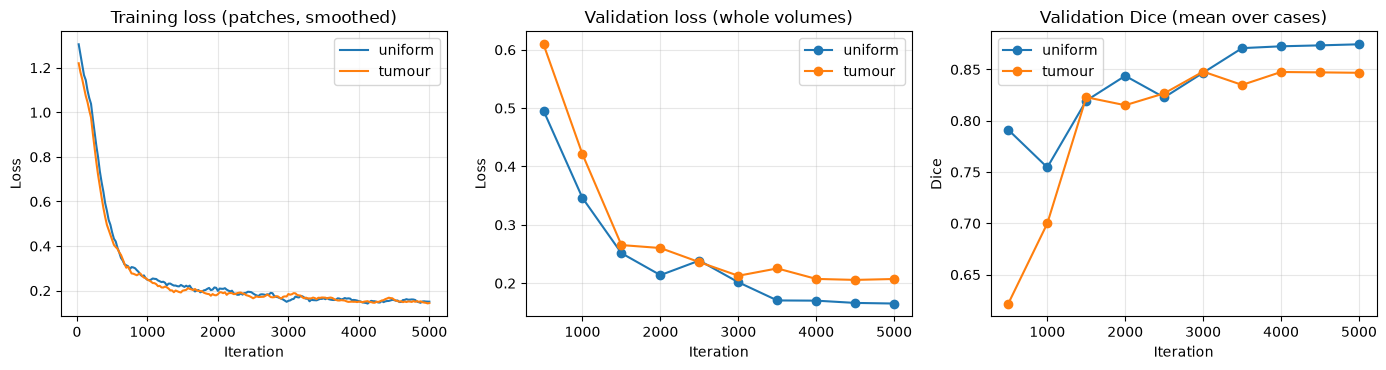

,iter,train_loss,val_loss,val_dice,val_dice_median,val_sens,val_fp_ml,lr,tumour_patch_frac,minutes
0,500,0.7371,0.4957,0.7911,0.8248,0.8552,22.4776,0.0010,0.9760,0.6143
1,1000,0.2852,0.3461,0.7546,0.8067,0.9331,41.9239,0.0009,0.9760,1.1497
2,1500,0.2314,0.2515,0.8196,0.8494,0.9033,25.7686,0.0008,0.9787,1.6837
3,2000,0.2022,0.2138,0.8438,0.8763,0.9123,21.4963,0.0007,0.9802,2.2202
4,2500,0.1910,0.2388,0.8227,0.8641,0.9357,29.2296,0.0005,0.9810,2.7501
5,3000,0.1699,0.2016,0.8468,0.8823,0.9208,21.8663,0.0004,0.9820,3.2861
6,3500,0.1655,0.1704,0.8708,0.8991,0.8766,12.1988,0.0002,0.9816,3.8210
7,4000,0.1587,0.1701,0.8726,0.8947,0.9111,16.4794,0.0001,0.9824,4.3559
8,4500,0.1503,0.1662,0.8735,0.8978,0.9045,15.1922,0.0000,0.9817,4.8898
9,5000,0.1553,0.1651,0.8745,0.8965,0.9114,15.6221,0.0000,0.9816,5.4207


In [28]:
colors = {"uniform": "tab:blue", "tumour": "tab:orange"}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))

for n in RUNS:
    tl = train_log[n]
    axs[0].plot(tl["iter"], tl["train_loss"].rolling(8, min_periods=1).mean(), color=colors[n], label=n)
    axs[1].plot(history[n]["iter"], history[n]["val_loss"], "o-", color=colors[n], label=n)
    axs[2].plot(history[n]["iter"], history[n]["val_dice"], "o-", color=colors[n], label=n)

axs[0].set_title("Training loss (patches, smoothed)")
axs[1].set_title("Validation loss (whole volumes)")
axs[2].set_title("Validation Dice (mean over cases)")
for a in axs:
    a.set_xlabel("Iteration"); a.grid(alpha=0.3); a.legend()
axs[0].set_ylabel("Loss"); axs[1].set_ylabel("Loss"); axs[2].set_ylabel("Dice")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

history["uniform"].round(4)

## Task E – Controlled sampling comparison

In [29]:
# Validation comparison of the two samplers: Dice, tumour sensitivity and false-positive volume
rows = []
for n in RUNS:
    h = history[n]
    best, last = h.loc[h.val_dice.idxmax()], h.iloc[-1]
    rows.append({"sampler": n,
                 "best iter": int(best["iter"]),
                 "val Dice (best)": best.val_dice, "sensitivity (best)": best.val_sens, "FP volume mL (best)": best.val_fp_ml,
                 "val Dice (last)": last.val_dice, "sensitivity (last)": last.val_sens, "FP volume mL (last)": last.val_fp_ml})
comparison = pd.DataFrame(rows).set_index("sampler").round(3)
comparison

,best iter,val Dice (best),sensitivity (best),FP volume mL (best),val Dice (last),sensitivity (last),FP volume mL (last)
sampler,,,,,,,
uniform,5000,0.875,0.911,15.622,0.875,0.911,15.622
tumour,3000,0.848,0.886,18.314,0.847,0.919,22.865


In [30]:
# Final configuration chosen from validation evidence only (highest validation Dice at the best checkpoint)
FINAL_SAMPLER = comparison["val Dice (best)"].idxmax()
print("Selected sampler:", FINAL_SAMPLER)
print("Checkpoint to use for test evaluation:", RUNS[FINAL_SAMPLER] / "best.pt")

with open(RUN_DIR / "selection.json", "w") as f:
    json.dump({"final_sampler": FINAL_SAMPLER, "checkpoint": str(RUNS[FINAL_SAMPLER] / "best.pt"),
               "criterion": "highest mean validation Dice at the best checkpoint"}, f, indent=2)

Selected sampler: uniform
Checkpoint to use for test evaluation: runs/uniform/best.pt


## Task E - Sampler comparison at a smaller patch size

In [31]:
PATCH_SMALL = (64, 64, 64)
RUN_DIR_SMALL = Path("runs_p64")
RUNS_SMALL = {"uniform": RUN_DIR_SMALL / "uniform", "tumour": RUN_DIR_SMALL / "tumour"}

CFG_SMALL = dict(TRAIN_CFG)
CFG_SMALL.update(patch_size=PATCH_SMALL, batch_size=6)

for name, path in RUNS_SMALL.items():
    if (path / "summary.json").exists():
        print(f"found finished run, skipping: {name}")
    else:
        a2_lib.train(dict(CFG_SMALL, sampler=name, out_dir=str(path)))

found finished run, skipping: uniform
found finished run, skipping: tumour


initial weights identical across all four runs
64^3 patches:
         patches containing tumour  mean tumour voxel fraction per patch
uniform                      0.720                                 0.055
tumour                       0.865                                 0.139


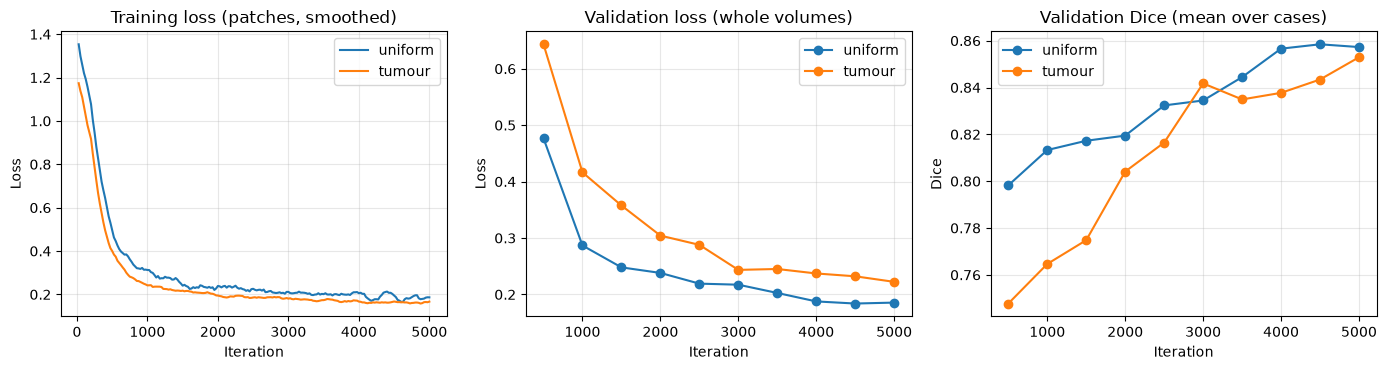

,best iter,val Dice (best),sensitivity (best),FP volume mL (best),val Dice (last),sensitivity (last),FP volume mL (last)
sampler,,,,,,,
uniform,4500,0.858,0.878,13.418,0.857,0.882,13.897
tumour,5000,0.853,0.889,15.815,0.853,0.889,15.815


In [32]:
# Load the records written by the 64^3 runs
assert all((p / "summary.json").exists() for p in RUNS_SMALL.values()), "64^3 runs missing: re-run the cell above."
hist_small = {n: pd.read_csv(p / "history.csv") for n, p in RUNS_SMALL.items()}
log_small = {n: pd.read_csv(p / "train_log.csv") for n, p in RUNS_SMALL.items()}
summ_small = {n: json.load(open(p / "summary.json")) for n, p in RUNS_SMALL.items()}

assert summ_small["uniform"]["init_hash"] == summ_small["tumour"]["init_hash"] == summary["uniform"]["init_hash"]
print("initial weights identical across all four runs")

def patch_tumour_stats_at(patch, sampler, n=400):
    ds = a2_lib.PatchDataset(CACHE_ROOT, train_ids, patch, n_samples=n, sampler=sampler,
                             p_tumour=TRAIN_CFG["p_tumour"], augment=False, seed=SEED)
    has_tumour, voxel_frac = [], []
    for i in range(n):
        _, y = ds[i]
        has_tumour.append(bool(y.sum() > 0))
        voxel_frac.append(float(y.mean()))
    return np.mean(has_tumour), np.mean(voxel_frac)

sampler_stats_small = pd.DataFrame(
    {s: patch_tumour_stats_at(PATCH_SMALL, s) for s in ["uniform", "tumour"]},
    index=["patches containing tumour", "mean tumour voxel fraction per patch"]).T.round(3)
print("64^3 patches:")
print(sampler_stats_small)

colors_small = {"uniform": "tab:blue", "tumour": "tab:orange"}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for n in RUNS_SMALL:
    tl = log_small[n]
    axs[0].plot(tl["iter"], tl["train_loss"].rolling(8, min_periods=1).mean(), color=colors_small[n], label=n)
    axs[1].plot(hist_small[n]["iter"], hist_small[n]["val_loss"], "o-", color=colors_small[n], label=n)
    axs[2].plot(hist_small[n]["iter"], hist_small[n]["val_dice"], "o-", color=colors_small[n], label=n)
axs[0].set_title("Training loss (patches, smoothed)")
axs[1].set_title("Validation loss (whole volumes)")
axs[2].set_title("Validation Dice (mean over cases)")
for a in axs:
    a.set_xlabel("Iteration"); a.grid(alpha=0.3); a.legend()
axs[0].set_ylabel("Loss"); axs[1].set_ylabel("Loss"); axs[2].set_ylabel("Dice")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_training_curves_p64.png", dpi=200, bbox_inches="tight")
plt.show()

rows_small = []
for n in RUNS_SMALL:
    h = hist_small[n]
    best, last = h.loc[h.val_dice.idxmax()], h.iloc[-1]
    rows_small.append({"sampler": n, "best iter": int(best["iter"]),
                       "val Dice (best)": best.val_dice, "sensitivity (best)": best.val_sens,
                       "FP volume mL (best)": best.val_fp_ml,
                       "val Dice (last)": last.val_dice, "sensitivity (last)": last.val_sens,
                       "FP volume mL (last)": last.val_fp_ml})
comparison_small = pd.DataFrame(rows_small).set_index("sampler").round(3)
comparison_small

In [33]:
# Compare all four trained configurations 
all_runs = {("uniform", 96): RUNS["uniform"], ("tumour", 96): RUNS["tumour"],
            ("uniform", 64): RUNS_SMALL["uniform"], ("tumour", 64): RUNS_SMALL["tumour"]}
rows_all = []
for (sampler, size), path in all_runs.items():
    h = pd.read_csv(path / "history.csv")
    best = h.loc[h.val_dice.idxmax()]
    rows_all.append({"sampler": sampler, "patch": size, "best iter": int(best["iter"]),
                     "val Dice": best.val_dice, "sensitivity": best.val_sens,
                     "FP volume mL": best.val_fp_ml, "run folder": str(path)})
all_df = pd.DataFrame(rows_all).sort_values("val Dice", ascending=False).reset_index(drop=True)
print(all_df.round(3).to_string(index=False))

best_row = all_df.iloc[0]
FINAL_SAMPLER = best_row["sampler"]
FINAL_PATCH = (int(best_row["patch"]),) * 3
FINAL_RUN_DIR = Path(best_row["run folder"])
print("\nFinal configuration:", FINAL_SAMPLER, "sampler,", FINAL_PATCH, "patches, checkpoint:", FINAL_RUN_DIR / "best.pt")

with open(RUN_DIR / "selection.json", "w") as f:
    json.dump({"final_sampler": FINAL_SAMPLER, "patch_size": list(FINAL_PATCH),
               "checkpoint": str(FINAL_RUN_DIR / "best.pt"),
               "criterion": "highest mean validation Dice at the best checkpoint, over all four runs"}, f, indent=2)

sampler  patch  best iter  val Dice  sensitivity  FP volume mL       run folder
uniform     96       5000     0.875        0.911        15.622     runs/uniform
uniform     64       4500     0.858        0.878        13.418 runs_p64/uniform
 tumour     64       5000     0.853        0.889        15.815  runs_p64/tumour
 tumour     96       3000     0.848        0.886        18.314      runs/tumour

Final configuration: uniform sampler, (96, 96, 96) patches, checkpoint: runs/uniform/best.pt


## Task F – Reconstruct and evaluate full volumes

In [34]:
OVERLAP = 0.5 
THRESHOLD = 0.5
INFER_BATCH = 4
MIN_COMPONENT_ML = 1.0

ckpt = torch.load(FINAL_RUN_DIR / "best.pt", map_location=device, weights_only=False)
assert tuple(ckpt["cfg"]["patch_size"]) == tuple(FINAL_PATCH), "checkpoint patch size differs from FINAL_PATCH"

# Rebuild the same architecture, load the trained weights and switch to evaluation mode
final_model = a2_lib.UNet3D(4, 1, ckpt["cfg"]["base_filters"], ckpt["cfg"]["depth"]).to(device)
final_model.load_state_dict(ckpt["model"])
final_model.eval()

stride = [max(1, int(round(p * (1 - OVERLAP)))) for p in FINAL_PATCH]
print("checkpoint            :", FINAL_RUN_DIR / "best.pt", f"(iteration {ckpt['iter']}, validation Dice {ckpt['val_dice']:.4f})")
print("sampler used in train :", FINAL_SAMPLER)
print("patch size (H, W, D)  :", FINAL_PATCH)
print("stride (voxels)       :", tuple(stride), f"-> overlap {int(OVERLAP * 100)}%")
print("blending rule         : mean of the window probabilities at every voxel, then threshold at", THRESHOLD)

checkpoint            : runs/uniform/best.pt (iteration 5000, validation Dice 0.8745)
sampler used in train : uniform
patch size (H, W, D)  : (96, 96, 96)
stride (voxels)       : (48, 48, 48) -> overlap 50%
blending rule         : mean of the window probabilities at every voxel, then threshold at 0.5


In [35]:
crop_box = {r.case_id: (int(r.lo0), int(r.hi0), int(r.lo1), int(r.hi1), int(r.lo2), int(r.hi2))
            for r in cache_df.itertuples()}
split_by_id = split_df.set_index("case_id")
native_spacing = list(geometry_counter)[0][1]
native_voxel_ml = float(np.prod(native_spacing)) / 1000.0

def predict_mask(cid):
    img_mm, _ = a2_lib.open_case(CACHE_ROOT, cid)
    prob = a2_lib.sliding_window_prob(final_model, img_mm, FINAL_PATCH, OVERLAP, device, INFER_BATCH, use_amp=True)
    return (prob > THRESHOLD).cpu().numpy()

def to_original_grid(mask_cropped, cid):
    x0, x1, y0, y1, z0, z1 = crop_box[cid]
    full = np.zeros(tuple(NATIVE_SHAPE), dtype=bool)
    full[x0:x1, y0:y1, z0:z1] = mask_cropped
    return full

def hd95_mm(pred, gt, spacing):
    if not pred.any() or not gt.any():
        return np.nan
    idx = np.where(pred | gt)
    sl = tuple(slice(max(int(i.min()) - 1, 0), int(i.max()) + 2) for i in idx)
    p, g = pred[sl], gt[sl]
    p_surf = p & ~ndi.binary_erosion(p)
    g_surf = g & ~ndi.binary_erosion(g)
    dist_to_g = ndi.distance_transform_edt(~g_surf, sampling=spacing)
    dist_to_p = ndi.distance_transform_edt(~p_surf, sampling=spacing)
    return float(max(np.percentile(dist_to_g[p_surf], 95), np.percentile(dist_to_p[g_surf], 95)))

def case_metrics(pred, gt, spacing):
    tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
    voxel_ml = float(np.prod(spacing)) / 1000.0
    pred_ml, gt_ml = int(pred.sum()) * voxel_ml, int(gt.sum()) * voxel_ml
    return dict(
        dice=2 * tp / (2 * tp + fp + fn) if (tp + fp + fn) > 0 else 1.0,
        iou=tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 1.0,
        sensitivity=tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        hd95_mm=hd95_mm(pred, gt, spacing),
        gt_ml=gt_ml, pred_ml=pred_ml, fp_ml=fp * voxel_ml,
        vol_err_ml=abs(pred_ml - gt_ml),
        vol_err_pct=100 * abs(pred_ml - gt_ml) / gt_ml,
        vol_err_signed_pct=100 * (pred_ml - gt_ml) / gt_ml,
        empty_pred=bool(pred.sum() == 0), tp=tp, fp=fp, fn=fn)

def remove_small_components(mask, min_voxels):
    labelled, n = ndi.label(mask, structure=np.ones((3, 3, 3)))
    if n <= 1:
        return mask
    sizes = np.bincount(labelled.ravel())
    keep = sizes >= min_voxels
    keep[0] = False
    keep[1 + int(np.argmax(sizes[1:]))] = True
    return keep[labelled]

# Run inference for a list of cases
def predict_split(case_ids):
    return {cid: predict_mask(cid) for cid in tqdm(case_ids, desc="sliding-window inference")}

# Compare predictions
def evaluate_masks(masks, case_ids):
    rows = []
    for cid in case_ids:
        lab = nib.load(DATA_ROOT / split_by_id.loc[cid, "label_relpath"])
        gt = np.asanyarray(lab.dataobj) > 0
        spacing = tuple(float(z) for z in lab.header.get_zooms()[:3])
        m = case_metrics(to_original_grid(masks[cid], cid), gt, spacing)
        m["case_id"] = cid
        rows.append(m)
    return pd.DataFrame(rows).set_index("case_id")

# Mean, standard deviation and median over cases for the four headline metrics
def summarise(df):
    out = {}
    for col, name in [("dice", "Dice"), ("iou", "IoU"), ("sensitivity", "Sensitivity"), ("hd95_mm", "HD95 (mm)")]:
        out[name] = {"mean": df[col].mean(), "SD": df[col].std(), "median": df[col].median()}
    return pd.DataFrame(out).T

In [36]:
min_voxels = int(round(MIN_COMPONENT_ML / native_voxel_ml))
val_ids = cache_df.loc[cache_df.split == "validation", "case_id"].tolist()

val_masks_raw = predict_split(val_ids)
val_masks_post = {cid: remove_small_components(m, min_voxels) for cid, m in val_masks_raw.items()}
val_raw = evaluate_masks(val_masks_raw, val_ids)
val_post = evaluate_masks(val_masks_post, val_ids)

val_check = pd.DataFrame({"before": val_raw[["dice", "hd95_mm", "fp_ml"]].mean(),
                          "after": val_post[["dice", "hd95_mm", "fp_ml"]].mean()})
val_check["change"] = val_check["after"] - val_check["before"]
print(val_check.round(4))

dice_change = val_check.loc["dice", "change"]
hd95_change = val_check.loc["hd95_mm", "change"]
KEEP_POSTPROC = bool(dice_change > 0 and hd95_change <= 0)
print(f"\nKeep the rule? {KEEP_POSTPROC}  (validation Dice change {dice_change:+.4f}, HD95 change {hd95_change:+.3f} mm)")

sliding-window inference: 100%|████████████████████████████████████████████████████████████████| 73/73 [00:23<00:00,  3.13it/s]


          before    after  change
dice      0.8832   0.8837  0.0005
hd95_mm  13.6655  11.8319 -1.8336
fp_ml    12.6631  12.5720 -0.0911

Keep the rule? True  (validation Dice change +0.0005, HD95 change -1.834 mm)


In [37]:
test_ids = cache_df.loc[cache_df.split == "test", "case_id"].tolist()
test_masks_raw = predict_split(test_ids)
test_masks_post = {cid: remove_small_components(m, min_voxels) for cid, m in test_masks_raw.items()}

test_raw = evaluate_masks(test_masks_raw, test_ids)
test_post = evaluate_masks(test_masks_post, test_ids)
test_raw.to_csv(RUN_DIR / "test_metrics_raw.csv")
test_post.to_csv(RUN_DIR / "test_metrics_postprocessed.csv")

summary_table = pd.concat({"before postprocessing": summarise(test_raw),
                           "after postprocessing": summarise(test_post)}, axis=1).round(3)
print(f"Test cases: {len(test_ids)} | SD is the sample standard deviation (ddof=1)")
print(summary_table)
print("\nempty predictions  before:", int(test_raw["empty_pred"].sum()), "| after:", int(test_post["empty_pred"].sum()))
print("cases with a valid HD95  before:", int(test_raw["hd95_mm"].notna().sum()), "| after:", int(test_post["hd95_mm"].notna().sum()))

test_final = test_post if KEEP_POSTPROC else test_raw
final_masks = test_masks_post if KEEP_POSTPROC else test_masks_raw
np.savez_compressed(RUN_DIR / "test_pred_masks_final.npz", **final_masks)
print("\nResults used in the report:", "After postprocessing" if KEEP_POSTPROC else "Before postprocessing (rule rejected on validation)")

sliding-window inference: 100%|████████████████████████████████████████████████████████████████| 73/73 [00:23<00:00,  3.10it/s]


Test cases: 73 | SD is the sample standard deviation (ddof=1)
            before postprocessing                after postprocessing         \
                             mean      SD median                 mean     SD   
Dice                        0.894   0.064  0.903                0.895  0.064   
IoU                         0.814   0.097  0.823                0.816  0.096   
Sensitivity                 0.903   0.083  0.929                0.903  0.083   
HD95 (mm)                   9.475  15.418  4.583                7.492  8.575   

                    
            median  
Dice         0.904  
IoU          0.825  
Sensitivity  0.929  
HD95 (mm)    4.690  

empty predictions  before: 0 | after: 0
cases with a valid HD95  before: 73 | after: 73

Results used in the report: After postprocessing


Absolute volume error (mL)   : mean 11.70 | SD 12.16 | median 6.96
Absolute volume error (%)    : mean 12.4 | SD 11.8 | median 9.9
Signed volume error (%, +=over-segmentation): mean 2.0 | median -0.9

10 cases with the largest percentage error (all cases are in runs/test_volume_errors.csv):
            gt_ml  pred_ml  vol_err_ml  vol_err_pct  vol_err_signed_pct
case_id                                                                
BRATS_078   85.08   130.90       45.81        53.84               53.84
BRATS_169   87.41    47.63       39.78        45.51              -45.51
BRATS_376   10.10    14.15        4.04        40.05               40.05
BRATS_366   89.19   123.46       34.27        38.42               38.42
BRATS_241  134.58   179.68       45.10        33.51               33.51
BRATS_168   40.45    52.28       11.83        29.24               29.24
BRATS_246   81.39    58.56       22.83        28.05              -28.05
BRATS_293   63.06    80.42       17.36        27.53         

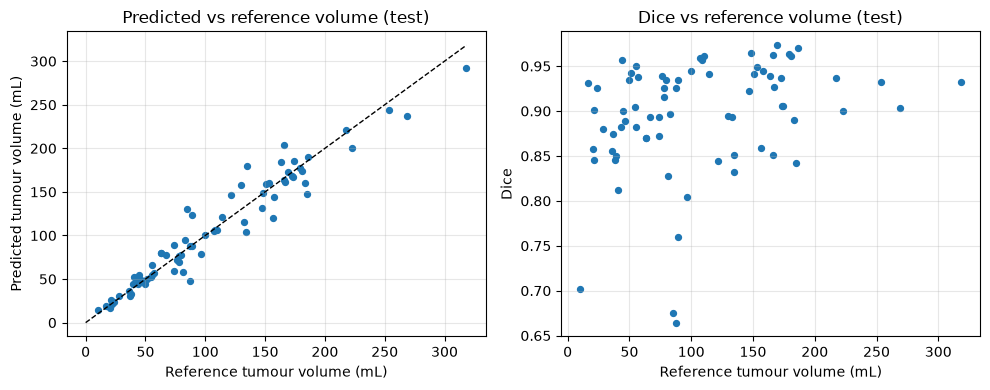


best  : BRATS_112 Dice 0.973
median: BRATS_253 Dice 0.904
worst : BRATS_169 Dice 0.664


In [38]:
vol_table = test_final[["gt_ml", "pred_ml", "vol_err_ml", "vol_err_pct", "vol_err_signed_pct"]].round(2)
vol_table.to_csv(RUN_DIR / "test_volume_errors.csv")
print("Absolute volume error (mL)   : mean %.2f | SD %.2f | median %.2f" % (
    vol_table.vol_err_ml.mean(), vol_table.vol_err_ml.std(), vol_table.vol_err_ml.median()))
print("Absolute volume error (%%)    : mean %.1f | SD %.1f | median %.1f" % (
    vol_table.vol_err_pct.mean(), vol_table.vol_err_pct.std(), vol_table.vol_err_pct.median()))
print("Signed volume error (%%, +=over-segmentation): mean %.1f | median %.1f" % (
    vol_table.vol_err_signed_pct.mean(), vol_table.vol_err_signed_pct.median()))
print("\n10 cases with the largest percentage error (all cases are in runs/test_volume_errors.csv):")
print(vol_table.sort_values("vol_err_pct", ascending=False).head(10))

# Predicted vs reference volume and Dice vs tumour size.
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].scatter(vol_table.gt_ml, vol_table.pred_ml, s=18)
top = float(max(vol_table.gt_ml.max(), vol_table.pred_ml.max()))
axs[0].plot([0, top], [0, top], "k--", linewidth=1)
axs[0].set_xlabel("Reference tumour volume (mL)"); axs[0].set_ylabel("Predicted tumour volume (mL)")
axs[0].set_title("Predicted vs reference volume (test)")
axs[1].scatter(vol_table.gt_ml, test_final.dice, s=18)
axs[1].set_xlabel("Reference tumour volume (mL)"); axs[1].set_ylabel("Dice")
axs[1].set_title("Dice vs reference volume (test)")
for a in axs:
    a.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_test_volume.png", dpi=200, bbox_inches="tight")
plt.show()

# Best, median and worst test cases by Dice, these are the three cases shown in the error analysis (Task G).
order = test_final.dice.sort_values()
worst_case, best_case = order.index[0], order.index[-1]
median_case = order.index[len(order) // 2]
print("\nbest  :", best_case, f"Dice {test_final.loc[best_case, 'dice']:.3f}")
print("median:", median_case, f"Dice {test_final.loc[median_case, 'dice']:.3f}")
print("worst :", worst_case, f"Dice {test_final.loc[worst_case, 'dice']:.3f}")

## Task G – Three-plane error analysis and limitations

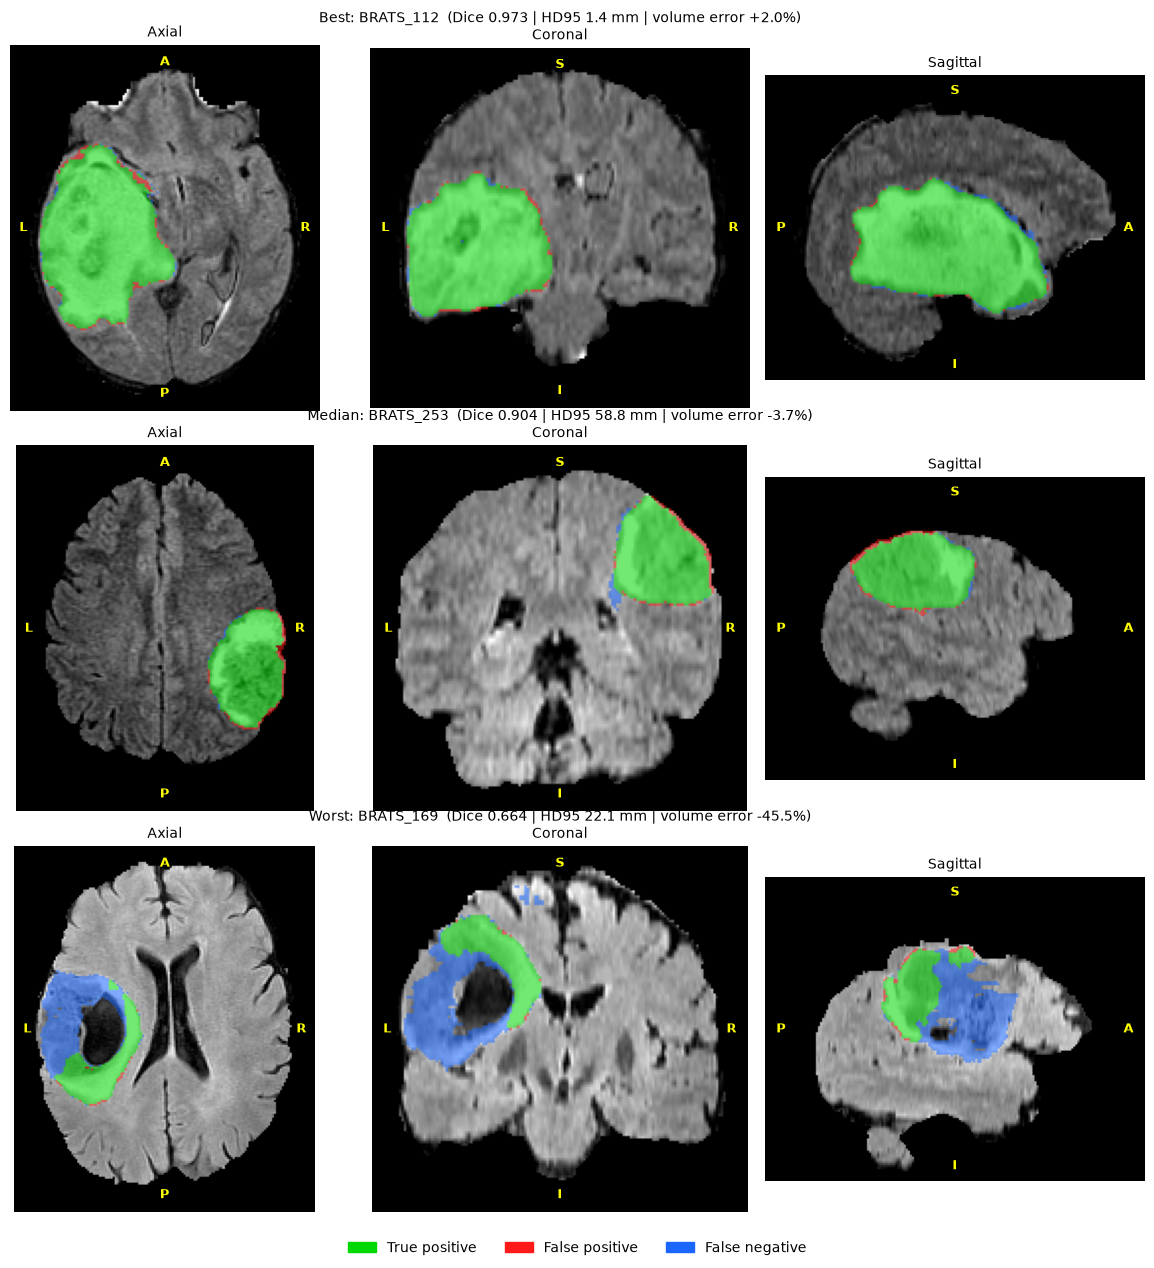

In [39]:
from matplotlib.patches import Patch

TP_COL, FP_COL, FN_COL = (0.0, 0.85, 0.0), (1.0, 0.1, 0.1), (0.1, 0.4, 1.0)
selected = [("Best", best_case), ("Median", median_case), ("Worst", worst_case)]

# Load FLAIR
def get_case_arrays(cid):
    img_mm, lab_mm = a2_lib.open_case(CACHE_ROOT, cid)
    flair = np.asarray(img_mm[0], dtype=np.float32)
    gt = np.asarray(lab_mm) > 0
    pred = final_masks[cid]
    return flair, gt, pred

def overlay_rgb(base2d, gt2d, pred2d, alpha=0.55):
    brain = base2d != 0
    g = np.zeros_like(base2d, dtype=np.float32)
    if brain.any():
        lo, hi = np.percentile(base2d[brain], [1, 99])
        g = np.clip((base2d - lo) / (hi - lo + 1e-8), 0, 1)
        g[~brain] = 0
    rgb = np.stack([g, g, g], axis=-1)
    tp, fp, fn = gt2d & pred2d, pred2d & ~gt2d, gt2d & ~pred2d
    for mask, colour in [(tp, TP_COL), (fp, FP_COL), (fn, FN_COL)]:
        rgb[mask] = (1 - alpha) * rgb[mask] + alpha * np.array(colour)
    return rgb

def error_centre(gt, pred):
    err = gt ^ pred
    if not err.any():
        return tuple(int(np.median(i)) for i in np.nonzero(gt))
    labelled, n = ndi.label(err, structure=np.ones((3, 3, 3)))
    sizes = np.bincount(labelled.ravel())
    sizes[0] = 0 
    biggest = labelled == int(np.argmax(sizes))
    return tuple(int(np.median(i)) for i in np.nonzero(biggest))

fig, axs = plt.subplots(3, 3, figsize=(12, 12.6))
for r, (tag, cid) in enumerate(selected):
    flair, gt, pred = get_case_arrays(cid)
    cx, cy, cz = error_centre(gt, pred)
    m = test_final.loc[cid]
    planes = [("Axial", (slice(None), slice(None), cz), ("A", "P", "L", "R")),
              ("Coronal", (slice(None), cy, slice(None)), ("S", "I", "L", "R")),
              ("Sagittal", (cx, slice(None), slice(None)), ("S", "I", "P", "A"))]
    for c, (pname, idx, dirs) in enumerate(planes):
        ax = axs[r, c]
        ax.imshow(np.rot90(overlay_rgb(flair[idx], gt[idx], pred[idx])))
        label_directions(ax, *dirs)
        ax.axis("off")
        ax.set_title(pname if c != 1 else
                     f"{tag}: {cid}  (Dice {m.dice:.3f} | HD95 {m.hd95_mm:.1f} mm | volume error {m.vol_err_signed_pct:+.1f}%)\n{pname}",
                     fontsize=10)
fig.legend(handles=[Patch(color=TP_COL, label="True positive"), Patch(color=FP_COL, label="False positive"),
                    Patch(color=FN_COL, label="False negative")], loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "fig_error_cases.png", dpi=200, bbox_inches="tight")
plt.show()

In [40]:
# The three selected cases side by side, overlap (Dice), boundary distance (HD95) and volume error
sel_ids = [best_case, median_case, worst_case]
three = test_final.loc[sel_ids, ["dice", "hd95_mm", "gt_ml", "pred_ml", "vol_err_ml", "vol_err_signed_pct"]].copy()
three["missed volume, FN (mL)"] = test_final.loc[sel_ids, "fn"] * native_voxel_ml
three["extra volume, FP (mL)"] = test_final.loc[sel_ids, "fp_ml"]
three.insert(0, "role", ["best", "median", "worst"])
print(three.round(3).to_string())

print("\nSpearman correlation across test cases:")
print(test_final[["dice", "hd95_mm", "vol_err_pct"]].corr(method="spearman").round(2))

# Examples showing why one metric cannot summarise every failure.
good_overlap_bad_boundary = test_final[(test_final.dice >= 0.90) & (test_final.hd95_mm >= 10)]
right_volume_low_overlap = test_final[(test_final.vol_err_pct < 5) & (test_final.dice < 0.85)]
print("\nHigh Dice (>= 0.90) but HD95 >= 10 mm (a distant fragment hurts HD95 but only slightly changes Dice):")
print(good_overlap_bad_boundary[["dice", "hd95_mm", "vol_err_pct"]].round(2) if len(good_overlap_bad_boundary) else "none")
print("\nVolume error < 5% but Dice < 0.85 (over- and under-segmentation cancel in the volume but not in the overlap):")
print(right_volume_low_overlap[["dice", "hd95_mm", "vol_err_pct"]].round(2) if len(right_volume_low_overlap) else "none")

             role   dice  hd95_mm    gt_ml  pred_ml  vol_err_ml  vol_err_signed_pct  missed volume, FN (mL)  extra volume, FP (mL)
case_id                                                                                                                           
BRATS_112    best  0.973    1.414  169.185  172.625       3.440               2.033                   2.848                  6.288
BRATS_253  median  0.904   58.827   54.356   52.367       1.989              -3.659                   6.101                  4.112
BRATS_169   worst  0.664   22.113   87.412   47.629      39.783             -45.512                  42.548                  2.765

Spearman correlation across test cases:
             dice  hd95_mm  vol_err_pct
dice          1.0    -0.70        -0.80
hd95_mm      -0.7     1.00         0.48
vol_err_pct  -0.8     0.48         1.00

High Dice (>= 0.90) but HD95 >= 10 mm (a distant fragment hurts HD95 but only slightly changes Dice):
           dice  hd95_mm  vol_err_pct
cas

In [41]:
# The separate pieces that the reference and prediction consist of in the median case
cid = median_case
_, lab_mm = a2_lib.open_case(CACHE_ROOT, cid)
gt = np.asarray(lab_mm) > 0
pred = final_masks[cid]
for name, m in [("reference", gt), ("prediction", pred)]:
    labelled, n = ndi.label(m, structure=np.ones((3, 3, 3)))
    sizes = np.bincount(labelled.ravel())[1:]
    order = np.argsort(sizes)[::-1]
    main_centre = np.argwhere(labelled == order[0] + 1).mean(0)
    print(f"{name}: {n} components")
    for k in order[:6]:
        centre = np.argwhere(labelled == k + 1).mean(0)
        dist = float(np.linalg.norm((centre - main_centre) * np.array(native_spacing)))
        print(f"  size {sizes[k] * native_voxel_ml:8.3f} mL | {dist:5.1f} mm from the main component")

reference: 7 components
  size   49.736 mL |   0.0 mm from the main component
  size    1.754 mL |  60.4 mm from the main component
  size    1.621 mL |  70.6 mm from the main component
  size    1.234 mL |  82.4 mm from the main component
  size    0.009 mL |  36.4 mm from the main component
  size    0.001 mL |  38.5 mm from the main component
prediction: 1 components
  size   52.367 mL |   0.0 mm from the main component


In [42]:
NEAR_MM = 2.0
rows_b = []
for cid in test_ids:
    _, lab_mm = a2_lib.open_case(CACHE_ROOT, cid)
    gt = np.asarray(lab_mm) > 0
    pred = final_masks[cid]
    gt_surface = gt & ~ndi.binary_erosion(gt)
    dist = ndi.distance_transform_edt(~gt_surface, sampling=native_spacing)
    fp, fn = pred & ~gt, gt & ~pred
    near = dist <= NEAR_MM
    n_err = int(fp.sum() + fn.sum())
    rows_b.append({"case_id": cid,
                   "error voxels": n_err,
                   "fraction within 2 mm of boundary": float((fp | fn)[near].sum()) / n_err if n_err else np.nan,
                   "missed deeper than 2 mm (mL)": float((fn & ~near).sum()) * native_voxel_ml,
                   "extra further than 2 mm (mL)": float((fp & ~near).sum()) * native_voxel_ml})
boundary_df = pd.DataFrame(rows_b).set_index("case_id")

print("Over all test cases, fraction of error voxels within 2 mm of the reference boundary:")
print(boundary_df["fraction within 2 mm of boundary"].describe().round(3))
print("\nBest / median / worst case:")
print(boundary_df.loc[sel_ids].round(3).to_string())

Over all test cases, fraction of error voxels within 2 mm of the reference boundary:
count    73.000
mean      0.871
std       0.128
min       0.454
25%       0.807
50%       0.913
75%       0.973
max       1.000
Name: fraction within 2 mm of boundary, dtype: float64

Best / median / worst case:
           error voxels  fraction within 2 mm of boundary  missed deeper than 2 mm (mL)  extra further than 2 mm (mL)
case_id                                                                                                              
BRATS_112          9136                             0.995                         0.032                         0.014
BRATS_253         10213                             0.952                         0.448                         0.039
BRATS_169         45313                             0.652                        15.751                         0.003
